#Loading setup

In [1]:
!pip install Bio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 321.4/321.4 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 kB 4.0 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import pandas as pd
import regex
from Bio import Entrez, SeqIO
import time
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import random as rand

%matplotlib inline

In [3]:
from google.colab import drive
drive.mount('/content/drive/')


#move to working directory:
%cd /content/drive/My Drive/Colab Notebooks/phages/PSI-BLAST-merge

!ls "./"

Mounted at /content/drive/
/content/drive/My Drive/Colab Notebooks/phages/PSI-BLAST-merge
 align-least-similar.txt	    GapRphage-with-hosts.csv
 align-longs.txt		    GapRvsHost.pdf
 align-most-similar.txt		    GapRvsPhage.pdf
 align-super-diff.txt		    GC-vs-host-byKR.pdf
 bact_length_hist.pdf		    host_GapR.fasta
'COG3750 hits.fasta'		    host_GCF.txt
'DUF2312 hits.fasta'		    host-genomes
 Figure1-FINAL.ipynb		    host-phage-count-heatmap.pdf
 Figure1-temp.ipynb		    host-phage-GC-KR.csv
 Figure6-FINAL.ipynb		    host-phage-GC_random_matrix_subplots.pdf
'Figure6-get genomes.ipynb'	    host-phage-GC_sampled_subplots.pdf
 Figure6-temp.ipynb		    host-phage-GC_subplots.pdf
 for-rands.pdf			    long-phage.csv
 GapR_GC_table.txt		   'PF10073 hits.fasta'
 GapR_host_aligned.fa		    phage-blast
 GapR_host-table.xlsx		    phage-genomes
 GapRphage.fasta		    phage-host-GC.pdf
 GapRphage-Figure1C.csv		    phage_host_length.pdf
 GapRphage-Figure1C.fasta	    phage_host_lengths.html
 GapRphage-Fig

#Figure 1A data

In [4]:
#List of merged 3xPSI-blast list with the NCBI/Uniprot UPF0335, PF10073, COG3750, and DUF2312 hit list, Uniprot UPF0335 is a subset of PF10073
all_protein_data = []
file_list = os.listdir('./phage-blast')
file_list = [os.path.join('./phage-blast', f) for f in file_list]
file_list.extend(['UPF0335 hits.fasta','PF10073 hits.fasta','COG3750 hits.fasta', 'DUF2312 hits.fasta', 'uniprotkb_PF10073.fasta'])

for file_name in file_list:
    file_path = os.path.join('.', file_name)
    current_protein_name = None
    current_sequence = []
    sequences_in_file = 0

    try:
        with open(file_path, 'r') as f:
            for line in f:
                line = line.strip()
                if line.startswith('>'):
                    if current_protein_name is not None:
                        all_protein_data.append({
                            'Protein Name': current_protein_name,
                            'Sequence': ''.join(current_sequence)
                        })
                        sequences_in_file += 1
                    current_protein_name = line[1:].strip()
                    current_sequence = []
                elif line:
                    current_sequence.append(line)

            # Add the last protein record from the current file
            if current_protein_name is not None:
                all_protein_data.append({
                    'Protein Name': current_protein_name,
                    'Sequence': ''.join(current_sequence)
                })
                sequences_in_file += 1
        print(f"File '{file_name}': {sequences_in_file} sequences found.")
    except FileNotFoundError:
        print(f"Warning: File '{file_name}' not found. Skipping.")

# Create a single DataFrame from all parsed data
df_all_proteins = pd.DataFrame(all_protein_data)

# Remove duplicate sequences
df_all_proteins_unique = df_all_proteins.drop_duplicates(subset=['Protein Name'])

num_duplicates = len(df_all_proteins) - len(df_all_proteins_unique)

#display(df_all_proteins_unique.head())
print(f"\nTotal sequences before deduplication: {len(df_all_proteins)}")
print(f"Number of duplicate sequences removed: {num_duplicates}")
print(f"Total unique protein sequences found: {len(df_all_proteins_unique)}")

File './phage-blast/GapR-Rphi-viruses.txt': 4 sequences found.
File './phage-blast/GapR-POI1126-seed.txt': 209 sequences found.
File './phage-blast/GapR-RHph_I1_9.txt': 209 sequences found.
File './phage-blast/GapR-S-ESS1.txt': 209 sequences found.
File './phage-blast/GapR-Atu_ph08.txt': 209 sequences found.
File './phage-blast/GapR-OLIVR5.txt': 209 sequences found.
File './phage-blast/GapR-vB_RleM_P10VF.txt': 209 sequences found.
File './phage-blast/GapR-phiM9.txt': 209 sequences found.
File './phage-blast/GapR-RL38J1.txt': 209 sequences found.
File './phage-blast/GapR-RHph_Y68.txt': 209 sequences found.
File './phage-blast/GapR-RHph_N34.txt': 209 sequences found.
File './phage-blast/GapR-vB_BpoS-Kikimora.txt': 209 sequences found.
File './phage-blast/GapR-7-7-1.txt': 209 sequences found.
File './phage-blast/GapR-P9VFCI.txt': 209 sequences found.
File './phage-blast/GapR-RL2RES.txt': 209 sequences found.
File './phage-blast/GapR-AF3.txt': 209 sequences found.
File './phage-blast/GapR-

###Remove non-GapRs from list

###not GapR, only homology to a1
>DAT18018.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]
>DAU26001.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]
>DAO61885.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]

###not GapR, only homology to a2/3
>YDF65664.1 MAG: hypothetical protein [Caudoviricetes sp.]
>XOR85947.1 MAG: hypothetical protein MSP1767_11 [Caudoviricetes sp.]

###not GapR, too short OR alternative structures
>DAZ56614.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]
>DAH78690.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]
>DAE29837.1 MAG TPA: hypothetical protein [virus sp. ctqEG8]

###no a3, not GapR
>DAR98600.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]

#Real borderline, but I'll keep
>YDF83759.1 MAG: hypothetical protein [Caudoviricetes sp.]
>URC15559.1 DNA binding protein [Octadecabacter Antarctic DB virus 2]


In [5]:
#drop above non-GapRs from matrix
GapRphage = df_all_proteins_unique
notGapR = GapRphage[GapRphage['Protein Name'].isin(['DAT18018.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]','DAU26001.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]','DAO61885.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]','YDF65664.1 MAG: hypothetical protein [Caudoviricetes sp.]','XOR85947.1 MAG: hypothetical protein MSP1767_11 [Caudoviricetes sp.]',
                                                    'DAZ56614.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]','DAH78690.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]','DAE29837.1 MAG TPA: hypothetical protein [virus sp. ctqEG8]','DAR98600.1 MAG TPA: UPF0335 protein [Caudoviricetes sp.]'])].index
GapRphage.drop(notGapR, inplace=True)
GapRphage.reset_index(drop=True, inplace=True)

/tmp/ipykernel_1132/1884322188.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  GapRphage.drop(notGapR, inplace=True)


###Remove truly redundant GapRs from matrix (multiple of same phage)
>QIW87757.1 hypothetical protein Ab1vBOLIVR5_gp109c [Agrobacterium phage OLIVR5]
>AFH19713.1 hypothetical protein 7-7-1_00015 [Agrobacterium phage 7-7-1]
>AGS81025.1 hypothetical protein [Caulobacter phage Cr30]
>AGH31493.1 hypothetical protein LOKG_00057 [Loktanella phage pCB2051-A]
>QGZ14014.1 UPF0335 protein [Rhizobium phage RL38J1]
>QIG73969.1 hypothetical protein EVC06_194 [Rhizobium phage RHph_N34]
>QIG73630.1 hypothetical protein EVC04_193 [Rhizobium phage RHph_I1_9]
>QIG71045.1 hypothetical protein EVB92_195 [Rhizobium phage RHph_I9]
>QIG68132.1 hypothetical protein EVB55_197 [Rhizobium phage RHph_Y68]
>QNH71963.1 hypothetical protein P9VFCI_053 [Rhizobium phage P9VFCI]
>QNH71546.1 hypothetical protein AF3_011 [Rhizobium phage AF3]
>QGZ14289.1 hypothetical protein RL2RES_157 [Rhizobium phage RL2RES]
>AIK68452.1 hypothetical protein P10VF_239 [Rhizobium phage vB_RleM_P10VF]
>AWY09466.1 hypothetical protein vB_RpoS-V16_30 [Ruegeria phage vB_RpoS-V16]
>AWY09067.1 hypothetical protein vBRpoSV11_27 [Ruegeria phage vB_RpoS-V11]
>AWY08903.1 hypothetical protein vBRpoSV18_27 [Ruegeria phage vB_RpoS-V18]
>AWY08731.1 hypothetical protein vBRpoSV7_28 [Ruegeria phage vB_RpoS-V7]
>AKE44825.1 hypothetical protein Sm_phiM9_198 [Sinorhizobium phage phiM9]
>AIM40693.1 DUF2312-domain containing protein [Sulfitobacter phage NYA-2014a]
>ARB05729.1 hypothetical protein [Synechococcus virus S-ESS1]
>AIT13262.1 hypothetical protein DSS3P1_27 [Ruegeria phage DSS3-P1]
>AAL49609.1 unknown [Sinorhizobium phage PBC5]
>CAO99336.1 hypothetical protein [Azospirillum phage Cd]

In [6]:
#drop redundant GapRs from matix
redundant = GapRphage[GapRphage['Protein Name'].isin(['QIW87757.1 hypothetical protein Ab1vBOLIVR5_gp109c [Agrobacterium phage OLIVR5]', 'AFH19713.1 hypothetical protein 7-7-1_00015 [Agrobacterium phage 7-7-1]', 'AGS81025.1 hypothetical protein [Caulobacter phage Cr30]', 'AGH31493.1 hypothetical protein LOKG_00057 [Loktanella phage pCB2051-A]', 'QGZ14014.1 UPF0335 protein [Rhizobium phage RL38J1]',
                                                      'QIG73969.1 hypothetical protein EVC06_194 [Rhizobium phage RHph_N34]', 'QIG73630.1 hypothetical protein EVC04_193 [Rhizobium phage RHph_I1_9]', 'QIG71045.1 hypothetical protein EVB92_195 [Rhizobium phage RHph_I9]', 'QIG68132.1 hypothetical protein EVB55_197 [Rhizobium phage RHph_Y68]',  'QNH71963.1 hypothetical protein P9VFCI_053 [Rhizobium phage P9VFCI]',
                                                      'QNH71546.1 hypothetical protein AF3_011 [Rhizobium phage AF3]', 'QGZ14289.1 hypothetical protein RL2RES_157 [Rhizobium phage RL2RES]', 'AIK68452.1 hypothetical protein P10VF_239 [Rhizobium phage vB_RleM_P10VF]', 'AWY09466.1 hypothetical protein vB_RpoS-V16_30 [Ruegeria phage vB_RpoS-V16]', 'AWY09067.1 hypothetical protein vBRpoSV11_27 [Ruegeria phage vB_RpoS-V11]',
                                                      'AWY08903.1 hypothetical protein vBRpoSV18_27 [Ruegeria phage vB_RpoS-V18]', 'AWY08731.1 hypothetical protein vBRpoSV7_28 [Ruegeria phage vB_RpoS-V7]', 'AKE44825.1 hypothetical protein Sm_phiM9_198 [Sinorhizobium phage phiM9]', 'AIM40693.1 DUF2312-domain containing protein [Sulfitobacter phage NYA-2014a]', 'ARB05729.1 hypothetical protein [Synechococcus virus S-ESS1]',
                                                      'AIT13262.1 hypothetical protein DSS3P1_27 [Ruegeria phage DSS3-P1]','AAL49609.1 unknown [Sinorhizobium phage PBC5]','CAO99336.1 hypothetical protein [Azospirillum phage Cd]'])].index
GapRphage.drop(redundant, inplace=True)
GapRphage.reset_index(drop=True, inplace=True)

#Calculate # of identified GapR for Figure 1A
len(GapRphage)

/tmp/ipykernel_1132/3102888498.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  GapRphage.drop(redundant, inplace=True)


288

In [7]:
#Call hosts from 'Protein Name' metadata if possible
hostname = []

exclusion_keywords = ['MAG', 'MAG:', 'uncultured', 'Prokaryotic', '[Caudoviricetes']

for index, row in GapRphage.iterrows():
    protein_name_words = row['Protein Name'].split(' ')

    if any(keyword in protein_name_words for keyword in exclusion_keywords):
        hostname.append('N/A')
    elif 'phage' in protein_name_words:
        phage_index = protein_name_words.index('phage')
        if phage_index > 0: # Ensure there's a word before 'phage'
            potential_host = protein_name_words[phage_index - 1]
            # Clean up potential_host, e.g., remove '[' and ']'
            cleaned_host = potential_host.replace('[', '').replace(']', '')
            hostname.append(cleaned_host)
        else:
            hostname.append('no host preceeding phage') # 'phage' is the first word, no preceding host
    else:
        hostname.append('something weird happened') # No specific host identified by the rules

GapRphage['host'] = hostname

GapRphage[GapRphage.host=='something weird happened'] #print this because i need to remember
#What I must fix these manually

/tmp/ipykernel_1132/796462514.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  GapRphage['host'] = hostname


,Protein Name,Sequence,host
28,ANR76363.1 hypothetical protein AUR56_00018 [S...,MTDETPGQGHNSYGLAAGELRQFIERVEHLEAEKREIAEQVKEVMA...,something weird happened
83,YP_009997121.1 hypothetical protein JT310_gp39...,MSSLSEIDDLLSGEDDSPGKGVDAAYRVTSQELRAFIERYERLQAE...,something weird happened
86,AEI71053.1 hypothetical protein [EBPR siphovir...,MARKPGEEPTSKDNGGDDPVAGDRLKTIAERINRLEEEKKAIADDI...,something weird happened
200,URC15559.1 DNA binding protein [Octadecabacter...,MTDIKQYIERRQRLEAEKQDAADNIKELNAEIKGNGHDIKAFNLVI...,something weird happened


In [8]:
#fixes the missing ones manually because they're weird.
GapRphage.loc[28, 'host'] = 'Skeletonema'
GapRphage.loc[83, 'host'] = 'Synechococcus'
GapRphage.loc[86, 'host'] = 'EBPR'
GapRphage.loc[200, 'host'] = 'Octadecabacter Antarctic DB'

#Figure S1A counts

In [9]:
#Attack NCBI to get the viral taxonomy information
Entrez.email = "msguo@uw.edu"

phagetaxonomy = []
#exclusion_keywords = ['']

for index, row in GapRphage.iterrows():
    protein_name_words = row['Protein Name'].split(' ')

    if any(keyword in protein_name_words for keyword in exclusion_keywords):
      hostname.append('N/A')
    else:
      accession = protein_name_words[0]

    try:
      handle = Entrez.efetch(db="protein", id=accession, rettype="xml")
      record = ET.parse(handle)
      root = record.getroot()
      # Extract taxonomy (includes host info for phages)
      taxonomy = root.find(".//GBSeq_taxonomy").text if root.find(".//GBSeq_taxonomy") is not None else None
      phagetaxonomy.append(taxonomy)
      time.sleep(0.5)  # Be nice to NCBI

    except:
      phagetaxonomy.append(accession)
      print('yikes!',accession)

GapRphage['taxonomy'] = phagetaxonomy

/tmp/ipykernel_1132/2255758594.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  GapRphage['taxonomy'] = phagetaxonomy


In [10]:
taxgroup = []
for index, row in GapRphage.iterrows():
  t = [x.strip() for x in row.taxonomy.split(';')]
  if 'Caudoviricetes' in t:
    t_index = t.index('Caudoviricetes')
    if t_index + 1 < len(t): # Check if there is an element after 'Caudoviricetes'
      tax = t[t_index + 1]
      if tax == 'Caudoviricetes incertae sedis':
        tax = t[t_index + 2]
        taxgroup.append(tax)
      else:
        taxgroup.append(tax)
    else: # 'Caudoviricetes' is the last element
      taxgroup.append('Caudoviricetes')
  else: # 'Caudoviricetes' does not appear in the list, add last element
    taxgroup.append(t[-1])

GapRphage['phagegroup'] = taxgroup

/tmp/ipykernel_1132/799124864.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  GapRphage['phagegroup'] = taxgroup


In [11]:
#Calculate phage taxonomy for Figure S1A
def categorize_phagegroup(group):
    if group in ['Peduoviridae', 'Casjensviridae', 'Pootjesviridae']:
        return group
    elif group in ['Caudoviricetes']:
        return 'unspecified Cauldoviricetes'
    elif group in ['Viruses']:
        return 'unspecified virus'
    else:
        return 'other'

categorized_phagegroup_series = GapRphage['phagegroup'].apply(categorize_phagegroup)
categorized_phagegroup_series.value_counts()

,count
phagegroup,
unspecified Cauldoviricetes,108
Peduoviridae,71
Casjensviridae,44
other,27
unspecified virus,23
Pootjesviridae,15


#Figure 1B length comparison

In [12]:
length = []
for index, row in GapRphage.iterrows():
  length.append(len(row.Sequence))

GapRphage['length'] = length

/tmp/ipykernel_1132/1343629369.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  GapRphage['length'] = length


In [13]:
current_protein_name = None
current_sequence = []
bact_protein_data = []

with open('./protein-matching-PF10073.fasta', 'r') as f:
        for line in f:
            line = line.strip()
            if line.startswith('>'):
                if current_protein_name is not None:
                    bact_protein_data.append({
                        'Protein Name': current_protein_name,
                        'Sequence': ''.join(current_sequence)
                    })
                current_protein_name = line[1:].strip()
                current_sequence = []
            elif line:
                current_sequence.append(line)

        # Add the last protein record after the loop finishes
        if current_protein_name is not None:
            bact_protein_data.append({
                'Protein Name': current_protein_name,
                'Sequence': ''.join(current_sequence)
            })

GapRbact = pd.DataFrame(bact_protein_data)

In [14]:
length = []
for index, row in GapRbact.iterrows():
  length.append(len(row.Sequence))

GapRbact['length'] = length

115.42708333333333 89.0 75.00556619969946
91.96480686695278 87.0 28.2585886332549


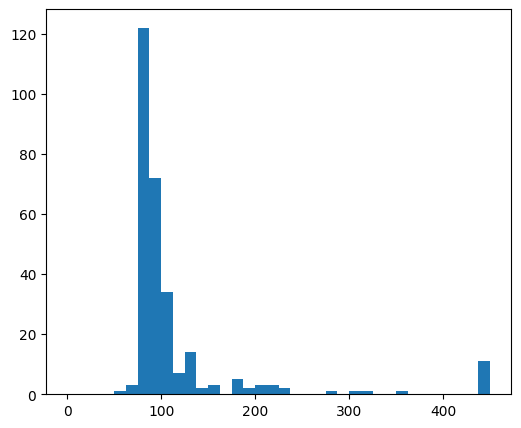

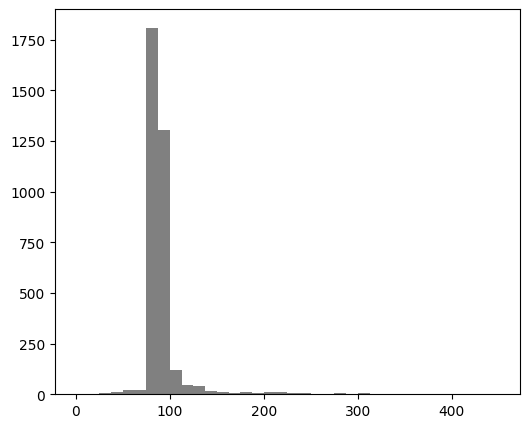

In [15]:
plt.figure(figsize=(6, 5))
bins = np.arange(0, 462.5, 12.5)
plt.hist(GapRphage.length, bins=bins)
print(np.mean(GapRphage.length), np.median(GapRphage.length), np.std(GapRphage.length))
plt.savefig('phage_length_hist.pdf')

plt.figure(figsize=(6, 5))
bins = np.arange(0, 462.5, 12.5)
plt.hist(GapRbact.length, bins=bins, color = 'grey')
print(np.mean(GapRbact.length), np.median(GapRbact.length), np.std(GapRbact.length))
plt.savefig('bact_length_hist.pdf')

#Figure 1C alignment

In [16]:
alignment_data = []
current_protein_name = None
current_aligned_sequence = []

file_path = 'align-most-similar.txt'

with open(file_path, 'r') as f:
    for line in f:
        line = line.strip()
        if line.startswith('>'):
            if current_protein_name is not None:
                alignment_data.append({
                    'Protein Name': current_protein_name,
                    'Aligned Sequence': ''.join(current_aligned_sequence)
                })
            current_protein_name = line[1:].strip()
            current_aligned_sequence = []
        elif line:
            current_aligned_sequence.append(line)

    # Add the last protein record after the loop finishes
    if current_protein_name is not None:
        alignment_data.append({
            'Protein Name': current_protein_name,
            'Aligned Sequence': ''.join(current_aligned_sequence)
        })

df_alignment = pd.DataFrame(alignment_data)

# Split the 'Aligned Sequence' into individual amino acid columns more efficiently
if not df_alignment.empty:
    # Create a DataFrame from the split sequences
    split_sequences_df = df_alignment['Aligned Sequence'].apply(lambda x: pd.Series(list(x)))
    # Rename columns to AA_1, AA_2, etc.
    split_sequences_df.columns = [f'AA_{i+1}' for i in range(split_sequences_df.shape[1])]

    # Concatenate 'Protein Name' with the new amino acid DataFrame
    df_alignment = pd.concat([df_alignment['Protein Name'], split_sequences_df], axis=1)

#find which one is NA1000
df_alignment[df_alignment['Protein Name'].str.contains('NA1000')]

,Protein Name,AA_1,AA_2,AA_3,AA_4,AA_5,AA_6,AA_7,AA_8,AA_9,...,AA_804,AA_805,AA_806,AA_807,AA_808,AA_809,AA_810,AA_811,AA_812,AA_813
135,GapR_NA1000/1-89,-,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-


In [17]:
# Select only the 'AA_' columns from the NA1000 row
aa_columns_data = df_alignment.iloc[135][df_alignment.iloc[135].index.str.startswith('AA_')]

#gotta find K34, 42, 49, 56, 59, 63, 66 in Ccres NA1000 GapR
#this converts to AA_458, AA_470, AA_477, AA_484, AA_487, AA_491, AA_495 for align-most-similar group
aa_columns_data[aa_columns_data != '-'][62:63]

,135
AA_491,R


In [18]:
#counts # of K/R in the selected aligned columns
selected_cols = ['Protein Name', 'AA_458', 'AA_470', 'AA_477', 'AA_484', 'AA_487', 'AA_491', 'AA_495']
df_subset = df_alignment[selected_cols].copy()
df_subset['KR_count'] = df_subset.apply(lambda row: row.isin(['K', 'R']).sum(), axis=1)
df_subset.columns = ['Protein Name','K34', 'K42', 'K49', 'K56', 'K59', 'R63', 'K66','KR_count']
df_subset[0:3]

,Protein Name,K34,K42,K49,K56,K59,R63,K66,KR_count
0,QXN71659.1/1-444 hypothetical protein RCKEMMY_...,K,S,K,K,R,K,A,5
1,"YDF65731.1/1-70 MAG: hypothetical protein, par...",K,K,K,K,K,R,A,6
2,QDP48421.1/1-80 MAG: putative double-stranded ...,K,K,K,K,R,A,K,6


In [19]:
#Now add in the rest of the phage sets
alignment_data = []
current_protein_name = None
current_aligned_sequence = []

file_path = 'align-least-similar.txt'

with open(file_path, 'r') as f:
    for line in f:
        line = line.strip()
        if line.startswith('>'):
            if current_protein_name is not None:
                alignment_data.append({
                    'Protein Name': current_protein_name,
                    'Aligned Sequence': ''.join(current_aligned_sequence)
                })
            current_protein_name = line[1:].strip()
            current_aligned_sequence = []
        elif line:
            current_aligned_sequence.append(line)

    # Add the last protein record after the loop finishes
    if current_protein_name is not None:
        alignment_data.append({
            'Protein Name': current_protein_name,
            'Aligned Sequence': ''.join(current_aligned_sequence)
        })

df_alignment = pd.DataFrame(alignment_data)

# Split the 'Aligned Sequence' into individual amino acid columns more efficiently
if not df_alignment.empty:
    # Create a DataFrame from the split sequences
    split_sequences_df = df_alignment['Aligned Sequence'].apply(lambda x: pd.Series(list(x)))
    # Rename columns to AA_1, AA_2, etc.
    split_sequences_df.columns = [f'AA_{i+1}' for i in range(split_sequences_df.shape[1])]

    # Concatenate 'Protein Name' with the new amino acid DataFrame
    df_alignment = pd.concat([df_alignment['Protein Name'], split_sequences_df], axis=1)

#find which one is NA1000
df_alignment[df_alignment['Protein Name'].str.contains('NA1000')]

,Protein Name,AA_1,AA_2,AA_3,AA_4,AA_5,AA_6,AA_7,AA_8,AA_9,...,AA_586,AA_587,AA_588,AA_589,AA_590,AA_591,AA_592,AA_593,AA_594,AA_595
16,GapR_NA1000/1-89,-,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-


In [20]:
# Select only the 'AA_' columns from the NA1000 row
aa_columns_data = df_alignment.iloc[16][df_alignment.iloc[16].index.str.startswith('AA_')]

#gotta find K34, 42, 49, 56, 59, 63, 66 in Ccres NA1000 GapR
#this converts to AA_248, AA_265, AA_272, AA_283, AA_286, AA_297, AA_300 for align-most-similar group
aa_columns_data[aa_columns_data != '-'][33:34]

,16
AA_248,K


In [21]:
#counts # of K/R in the selected aligned columns
selected_cols = ['Protein Name', 'AA_248', 'AA_265', 'AA_272', 'AA_283', 'AA_286', 'AA_297', 'AA_300']
df_subset_short = df_alignment[selected_cols].copy()
df_subset_short['KR_count'] = df_subset_short.apply(lambda row: row.isin(['K', 'R']).sum(), axis=1)
df_subset_short.columns = ['Protein Name','K34', 'K42', 'K49', 'K56', 'K59', 'R63', 'K66','KR_count']
df_subset_short[0:3]

,Protein Name,K34,K42,K49,K56,K59,R63,K66,KR_count
0,DAM69665.1/1-177 MAG TPA: UPF0335 protein [Cau...,M,R,K,Q,P,E,K,3
1,DAL81869.1/1-177 MAG TPA: UPF0335 protein [Cau...,M,R,K,Q,P,E,K,3
2,DAY78728.1/1-177 MAG TPA: UPF0335 protein [Cau...,M,R,K,Q,P,E,K,3


In [22]:
#Now add in the rest of the phage sets
alignment_data = []
current_protein_name = None
current_aligned_sequence = []

file_path = 'align-super-diff.txt'

with open(file_path, 'r') as f:
    for line in f:
        line = line.strip()
        if line.startswith('>'):
            if current_protein_name is not None:
                alignment_data.append({
                    'Protein Name': current_protein_name,
                    'Aligned Sequence': ''.join(current_aligned_sequence)
                })
            current_protein_name = line[1:].strip()
            current_aligned_sequence = []
        elif line:
            current_aligned_sequence.append(line)

    # Add the last protein record after the loop finishes
    if current_protein_name is not None:
        alignment_data.append({
            'Protein Name': current_protein_name,
            'Aligned Sequence': ''.join(current_aligned_sequence)
        })

df_alignment = pd.DataFrame(alignment_data)

# Split the 'Aligned Sequence' into individual amino acid columns more efficiently
if not df_alignment.empty:
    # Create a DataFrame from the split sequences
    split_sequences_df = df_alignment['Aligned Sequence'].apply(lambda x: pd.Series(list(x)))
    # Rename columns to AA_1, AA_2, etc.
    split_sequences_df.columns = [f'AA_{i+1}' for i in range(split_sequences_df.shape[1])]

    # Concatenate 'Protein Name' with the new amino acid DataFrame
    df_alignment = pd.concat([df_alignment['Protein Name'], split_sequences_df], axis=1)

#find which one is NA1000
df_alignment[df_alignment['Protein Name'].str.contains('NA1000')]

,Protein Name,AA_1,AA_2,AA_3,AA_4,AA_5,AA_6,AA_7,AA_8,AA_9,...,AA_146,AA_147,AA_148,AA_149,AA_150,AA_151,AA_152,AA_153,AA_154,AA_155
2,GapR_NA1000/1-89,M,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-


In [23]:
# Select only the 'AA_' columns from the NA1000 row
aa_columns_data = df_alignment.iloc[2][df_alignment.iloc[2].index.str.startswith('AA_')]

#gotta find K34, 42, 49, 56, 59, 63, 66 in Ccres NA1000 GapR
#this converts to AA_68, AA_80, AA_88, AA_99, AA_102, AA_106, AA_116 for align-most-similar group
aa_columns_data[aa_columns_data != '-'][65:66]

,2
AA_116,K


In [24]:
#counts # of K/R in the selected aligned columns
selected_cols = ['Protein Name', 'AA_68', 'AA_80', 'AA_88', 'AA_99', 'AA_102', 'AA_106', 'AA_116']
df_subset_diff = df_alignment[selected_cols].copy()
df_subset_diff['KR_count'] = df_subset_diff.apply(lambda row: row.isin(['K', 'R']).sum(), axis=1)
df_subset_diff.columns = ['Protein Name','K34', 'K42', 'K49', 'K56', 'K59', 'R63', 'K66','KR_count']
df_subset_diff[0:3]

,Protein Name,K34,K42,K49,K56,K59,R63,K66,KR_count
0,UWI15344.1/1-101 MAG: protein of unknown funct...,I,K,Q,K,K,A,E,3
1,UWG72912.1/1-101 MAG: protein of unknown funct...,I,K,Q,K,K,A,E,3
2,GapR_NA1000/1-89,K,K,K,K,K,R,K,7


In [25]:
df_all = pd.concat([df_subset, df_subset_short, df_subset_diff])
df_all = df_all.drop_duplicates(subset=['Protein Name'], keep='first')
df_all = df_all.reset_index(drop=True)
df_all[0:3]

,Protein Name,K34,K42,K49,K56,K59,R63,K66,KR_count
0,QXN71659.1/1-444 hypothetical protein RCKEMMY_...,K,S,K,K,R,K,A,5
1,"YDF65731.1/1-70 MAG: hypothetical protein, par...",K,K,K,K,K,R,A,6
2,QDP48421.1/1-80 MAG: putative double-stranded ...,K,K,K,K,R,A,K,6


In [26]:
#generate merge
protAccessions = []
for index, row in df_all.iterrows():
  protAccessions.append(row['Protein Name'].split('/')[0].strip())

df_all['Protein Acession'] = protAccessions

protAccessions = []
for index, row in GapRphage.iterrows():
  protAccessions.append(row['Protein Name'].split(' ')[0].strip())

GapRphage['Protein Acession'] = protAccessions

GapRphage = GapRphage.merge(df_all[['Protein Acession', 'KR_count']], on='Protein Acession', how='left')

/tmp/ipykernel_1132/2381519653.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  GapRphage['Protein Acession'] = protAccessions


In [27]:
#Calculate phage # of DNA-binding residues for Figure 1C
GapRphage.KR_count.value_counts()

,count
KR_count,
6,121
7,73
5,50
4,26
3,18


#Figure 1D alignment

In [28]:
#output sequences in fasta format for MAFFT alignment
with open('./GapRphage-Figure1D.fasta', 'w') as f:
    for index, row in GapRphage.iterrows():
        f.write(f">{row['Protein Name']}\n")
        f.write(f"{row['Sequence']}\n")
f.close()

#Figure S1C

In [29]:
#output sequences in fasta format for KR<=3 for Figure S1C
with open('./GapRphage-FigureS1C.fasta', 'w') as f:
    for index, row in GapRphage[GapRphage['KR_count']<=3].iterrows():
        f.write(f">{row['Protein Name']}\n")
        f.write(f"{row['Sequence']}\n")
f.close()

#Save Final GapR Phage Matrix

In [30]:
GapRphage[0:3]

,Protein Name,Sequence,host,taxonomy,phagegroup,length,Protein Acession,KR_count
0,YP_009603833.1 hypothetical protein FDH82_gp26...,MNVNRDYDQLRAYLSLLVELECQIDEINEAKGQAFREAKACGFPRD...,Roseobacter,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Xiamenvirus,83,YP_009603833.1,3
1,YP_004421798.1 hypothetical protein RDJLphi1_g...,MNVNRDYDQLRAYLSLLVELECQIDEINEAKGQAFREAKACGFPRD...,Roseobacter,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Xiamenvirus,83,YP_004421798.1,3
2,UFK26709.1 hypothetical protein [Roseobacter p...,MKHNPNRDYDQLRAYLAALAELEHQIDEINEVKGRLFREARACGFE...,Roseobacter,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Xiamenvirus,84,UFK26709.1,3


In [31]:
GapRphage.to_csv('GapRphage-Figure1.csv')